<a href="https://colab.research.google.com/github/donggeunlee77/MONAI-tutorial-exercise/blob/main/MONAI%20-%202D%20classification%20tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!python -c "import monai" || pip install -q "monai-weekly[pillow, tqdm]"
!python -c "import matplotlib" || pip install -q matplotlib
%matplotlib inline

Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import monai
ModuleNotFoundError: No module named 'monai'


이거는 기본설정. 에러 일부 떠도 괜춘함

In [2]:
import os
import shutil
import tempfile
import matplotlib.pyplot as plt
import PIL     ## PIL: Python Imaging Library의 약자로, 이미지 파일을 읽고 변환하는 기능을 제공해. 현재는 Pillow라는 라이브러리로 유지되고 있어.
import torch
from torch.utils.tensorboard import SummaryWriter   ## TensorBoard에 학습 결과 기록
import numpy as np
from sklearn.metrics import classification_report   ## 분류 모델의 성능 평가

from monai.apps import download_and_extract
from monai.config import print_config
from monai.data import decollate_batch, DataLoader
from monai.metrics import ROCAUCMetric
from monai.networks.nets import DenseNet121
from monai.transforms import (
    Activations,
    EnsureChannelFirst,
    AsDiscrete,
    Compose,
    LoadImage,
    RandFlip,
    RandRotate,
    RandZoom,
    ScaleIntensity,
)

from monai.utils import set_determinism

print_config()


MONAI version: 1.7.dev2645
Numpy version: 2.4.6
Pytorch version: 2.14.1+cu130
MONAI flags: HAS_EXT=False, USE_COMPILED=False, USE_META_DICT=False
MONAI rev id: ed1d0c3cb86b2cfe223a7c845bec698dedbfa614
MONAI __file__: /usr/local/lib/python3.13/dist-packages/monai/__init__.py

Optional dependencies:
Pytorch Ignite version: NOT INSTALLED or UNKNOWN VERSION.
ITK version: NOT INSTALLED or UNKNOWN VERSION.
Nibabel version: 5.4.2
scikit-image version: 0.25.2
scipy version: 1.16.3
Pillow version: 11.3.0
Tensorboard version: 2.21.0
gdown version: 5.2.2
TorchVision version: 0.29.1+cu130
tqdm version: 4.67.3
lmdb version: NOT INSTALLED or UNKNOWN VERSION.
psutil version: 5.9.5
pandas version: 2.2.3
einops version: 0.8.2
transformers version: 5.22.1
mlflow version: NOT INSTALLED or UNKNOWN VERSION.
pynrrd version: NOT INSTALLED or UNKNOWN VERSION.
clearml version: NOT INSTALLED or UNKNOWN VERSION.

For details about installing the optional dependencies, please visit:
    https://monai.readthedocs.

classification_report : 분류모델의 성능평가

출력되는 주요 지표는 다음과 같아.

Precision	: 양성이라고 예측한 것 중 실제 양성 비율

Recall :	실제 양성 중 모델이 찾아낸 비율

F1-score:	Precision과 Recall의 조화평균

Support	: 해당 클래스의 실제 데이터 수

MONAI 모듈	기능

download_and_extract :	데이터셋 다운로드 및 압축 해제

print_config :	MONAI 및 관련 환경 정보 출력

decollate_batch	: Batch 데이터를 개별 데이터로 분리

DataLoader :	학습 데이터를 Batch 단위로 공급

ROCAUCMetric	: ROC-AUC 계산

DenseNet121 :	DenseNet121 신경망 모델

MONAI.transform : 전처리와 데이터 증강을 담당함.

- LoadImage	이미지 로딩
- EnsureChannelFirst	Channel 차원을 첫 번째 위치로 정렬
- Compose	여러 전처리 과정을 하나로 연결
- ScaleIntensity	영상 밝기값 정규화
- RandFlip	무작위 좌우 또는 상하 반전
- RandRotate	무작위 회전
- RandZoom	무작위 확대 및 축소
- Activations	Softmax, Sigmoid 등의 활성화 함수 적용
- AsDiscrete	확률 또는 예측값을 이산적인 클래스로 변환


set_determinism : 재현가능한 실험을 위한 함수. Random seed 설정

print_config()는 현재 설치된 MONAI, PyTorch, CUDA 등의 버전과 환경 정보를 출력해.

In [3]:
## Setup data directory
## 환경변수에 지정된 데이터 저장 경로가 있으면 그곳을 사용하고, 없으면 임시 폴더를 만들어 사용하겠다는 것
## You can specify a directory with the MONAI_DATA_DIRECTORY environment variable.

directory = os.environ.get("MONAI_DATA_DIRECTORY")  ## MONAI_DATA_DIRECTORY 환경변수가 설정돼있으면 그걸 반환, 없으면 None 반환
if directory is not None:
  os.makedirs(directory, exist_ok=True)
root_dir = tempfile.mkdtemp() if directory is None else directory  ## tempfile.mkdtemp()는 운영체제에서 임시 디렉터리를 생성하고 그 경로를 반환하는 함수야. 환경변수가 없으면 임시폴더경로, 있으면 지정된 데이터폴더경로를 root_dir로 지정하겠단 것
print(root_dir)

/tmp/tmphppo9w4z


In [4]:
## Download dataset : MedNIST

resource = "https://github.com/Project-MONAI/MONAI-extra-test-data/releases/download/0.8.1/MedNIST.tar.gz"
md5 = "0bc7306e7427e00ad1c5526a6677552d"

compressed_file = os.path.join(root_dir, "MedNIST.tar.gz")  ## 압축파일이 저장될 경로를 지정
data_dir = os.path.join(root_dir, "MedNIST")  ## 압축 해제후 데이터가 저장될 경로
if not os.path.exists(data_dir):
  download_and_extract(resource, compressed_file, root_dir, md5, "md5")   ## MedNIST 폴더가 존재하지 않는다면 다운로드 및 압축해제를 실행해라


MedNIST.tar.gz: 59.0MB [00:02, 27.5MB/s]                            


2026-11-11 04:10:48,523 - INFO - Verified 'MedNIST.tar.gz', md5: 0bc7306e7427e00ad1c5526a6677552d.
2026-11-11 04:10:48,524 - INFO - Downloaded: /tmp/tmphppo9w4z/MedNIST.tar.gz
2026-11-11 04:10:48,525 - INFO - Writing into directory: /tmp/tmphppo9w4z.


MD5는 Message Digest Algorithm 5의 약자야.

다운로드한 파일이 원본과 동일한지 확인하는 체크섬(checksum)이야.

예를 들어 다운로드 도중 파일이 손상되거나 일부 데이터가 변경되었다면 MD5 값이 달라질 수 있어.

즉, 데이터셋의 무결성을 확인하기 위한 장치야.

download_and_extract 함수
- 1번째 인자 : 다운로드할 인터넷 주소
- 2번째 인자 : 다운로드한 압축파일의 저장위치
- 3번째 인자 : 압축 해제할 위치
- 4번째 인자 : 파일 무결성 확인용 해시값
- 5번째 인자 : 사용할 체크섬 알고리즘

In [5]:
set_determinism(seed=0)

잠시 샛길. 아래에선 기본적인 폴더탐색 with chatGPT

In [6]:
print(root_dir)
print(os.listdir(root_dir)) ## os.listdir(path)	는 해당 폴더 내부의 파일·폴더 목록을 나타내줌.
print(os.listdir(data_dir))
print(os.listdir(os.path.join(data_dir, "Hand")))

/tmp/tmphppo9w4z
['MedNIST', 'MedNIST.tar.gz']
['Hand', 'README.md', 'AbdomenCT', 'BreastMRI', 'ChestCT', 'HeadCT', 'CXR']
['000742.jpeg', '003170.jpeg', '009756.jpeg', '007521.jpeg', '006897.jpeg', '008040.jpeg', '001016.jpeg', '003258.jpeg', '006365.jpeg', '001428.jpeg', '005164.jpeg', '001892.jpeg', '001753.jpeg', '003825.jpeg', '006642.jpeg', '007473.jpeg', '001508.jpeg', '002861.jpeg', '007816.jpeg', '008115.jpeg', '000053.jpeg', '007516.jpeg', '000844.jpeg', '002601.jpeg', '003223.jpeg', '005055.jpeg', '004181.jpeg', '001154.jpeg', '002604.jpeg', '009487.jpeg', '007094.jpeg', '001381.jpeg', '004847.jpeg', '001616.jpeg', '006405.jpeg', '003971.jpeg', '008903.jpeg', '002901.jpeg', '004192.jpeg', '006740.jpeg', '007455.jpeg', '006347.jpeg', '003325.jpeg', '005654.jpeg', '003016.jpeg', '002041.jpeg', '007509.jpeg', '003877.jpeg', '006689.jpeg', '005285.jpeg', '000046.jpeg', '009276.jpeg', '002039.jpeg', '003636.jpeg', '004119.jpeg', '001791.jpeg', '005990.jpeg', '005038.jpeg', '00191

In [7]:
for class_name in os.listdir(data_dir):
  class_path = os.path.join(data_dir, class_name)
  if os.path.isdir(class_path):  ## 해당 경로가 디렉터리인지 확인
    images = os.listdir(class_path)
    print(f"{class_name}: {len(images)} images")

Hand: 10000 images
AbdomenCT: 10000 images
BreastMRI: 8954 images
ChestCT: 10000 images
HeadCT: 10000 images
CXR: 10000 images


/tmp/tmphppo9w4z/MedNIST/ChestCT 000742.jpeg
/tmp/tmphppo9w4z/MedNIST/ChestCT/000742.jpeg


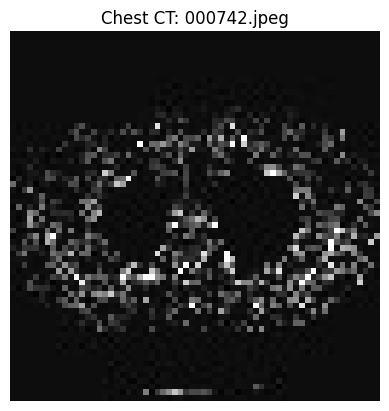

In [8]:
##이미지 하나 열어보기

from PIL import Image
import matplotlib.pyplot as plt

class_path = os.path.join(data_dir, "ChestCT")
image_name = os.listdir(class_path)[0]
print(class_path, image_name)

image_path = os.path.join(class_path, image_name)
print(image_path)

img = Image.open(image_path)

plt.imshow(img, cmap='gray')
plt.title(f"Chest CT: {image_name}")
plt.axis('off')
plt.show()

자 다시 돌아와서

In [9]:
os.listdir(data_dir)

['Hand', 'README.md', 'AbdomenCT', 'BreastMRI', 'ChestCT', 'HeadCT', 'CXR']

In [10]:
class_names = sorted(x for x in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, x))) ## data_dir 폴더의 하위폴더 이름들을 알파벳순으로 정렬. data_dir 안에 바로 들어있는 파일이 있다면 제외하기 위해 isdir을 쓴것
num_class = len(class_names)
image_files = [
    [os.path.join(data_dir, class_names[i], x) for x in os.listdir(os.path.join(data_dir, class_names[i]))]
    for i in range(num_class)
] ## class_names 별 이미지 파일의 path list

num_each = [len(image_files[i]) for i in range(num_class)]
image_files_list = []
image_class = []

for i in range(num_class):
  image_files_list.extend(image_files[i])  ##image_file는 class_names 별로 있는데, 그걸 그냥 순서대로 한 리스트에 쭉 붙여넣은것인듯
  image_class.extend([i] * num_each[i])  ## Python에서 리스트에 숫자를 곱하면 해당 리스트가 숫자 횟수 만큼 반복돼. 즉 image_files_list 내부 각각 원소에 대응하는 class를 붙여준것
## extend()는 기존 리스트에 다른 리스트의 원소들을 하나씩 추가하는 함수야.
## print(image_files_list[0:5], image_class[0:5])

num_total = len(image_class)

image_width, image_height = PIL.Image.open(image_files_list[0]).size  ## 우항 PIL.Image.open(~).size가 기본적으로 (width, height) 형태로 반환해주므로

print(f"Total image count: {num_total}")
print(f"Image dimensions: {image_width} x {image_height}")
print(f"Label names: {class_names}")
print(f"Label count: {num_each}")

Total image count: 58954
Image dimensions: 64 x 64
Label names: ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']
Label count: [10000, 8954, 10000, 10000, 10000, 10000]


Nested List Comprehension
image_files = [
  [내부 반복문]
  외부 반복문
]
이 구조로, 외부 반복문은 각 클래스 폴더를 순회, 내부 반복문은 해당 클래스 폴더 안의 파일을 순회. 즉 클래스별로 파일 목록을 만드는 구조

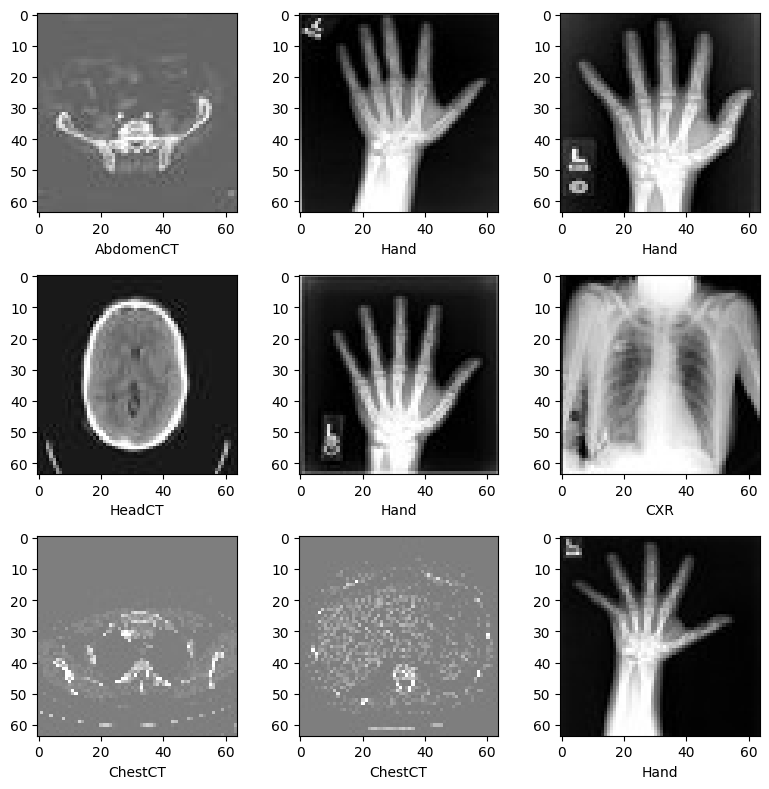

In [11]:
## Randomly pick images from the dataset to visualize and check

plt.subplots(3, 3, figsize=(8,8)) ##격자공간 준비
for i, k in enumerate(np.random.randint(num_total, size=9)): ## enumerate는 for 구문에서 index 와 원소를 함께 가져와줌.
  im = PIL.Image.open(image_files_list[k])
  arr = np.array(im) ## 이렇게 numpy array로 변환해야함!!
  plt.subplot(3, 3, i+1) ## 3×3 격자 중에서 몇 번째 위치에 이미지를 표시할 것인지 지정해. 위치번호는 1부터 시작하기 때문에 i+1 로 해줌
  plt.xlabel(class_names[image_class[k]])
  plt.imshow(arr, cmap='gray', vmin=0, vmax=255)
plt.tight_layout()
plt.show()



In [12]:
## Prepare training, validation and test data lists
## Randomly select 10% of the dataset as validation and 10% as test.

val_frac = 0.1
test_frac = 0.1
length = len(image_files_list)
indices = np.arange(length)  ## 0부터 length까지 1씩 늘어나는 배열 생성
np.random.shuffle(indices) ## indices는 인제 랜덤으로 셔플됨

test_split = int(test_frac * length)
test_indices = indices[:test_split]
val_split = int(val_frac * length) + test_split
val_indices = indices[test_split:val_split]
train_indices = indices[val_split:]

## 이까지는 랜덤숫자인 indices를 비율대로 순차적으로 잘라준것.

train_x = [image_files_list[i] for i in train_indices]
train_y = [image_class[i] for i in train_indices]
val_x = [image_files_list[i] for i in val_indices]
val_y = [image_class[i] for i in val_indices]
test_x = [image_files_list[i] for i in test_indices]
test_y = [image_class[i] for i in test_indices]

print(f"Training count : {len(train_x)}, Validation count : {len(val_x)}, Test count : {len(test_x)}")

Training count : 47164, Validation count : 5895, Test count : 5895


# Define MONAI transforms, Dataset and Dataloader to pre-process data

In [14]:
## transform 정의하기
train_transforms = Compose( ## Compose는 여러 가지 이미지 변환 과정을 하나로 묶어 순서대로 실행하게 해주는 MONAI의 기능이야.
    [LoadImage(image_only=True),  ## 이미지 파일을 실제로 불러오는 기능. MONAI의 LoadImage는 다양한 의료영상 포맷을 지원한다는 장점이 있다. image_only=True는 이미지 데이터만 반환하겠다는 뜻.
    EnsureChannelFirst(),  ## 채널 차원을 맨 앞에 배치하라고 (C, H, W) 예를들어 흑백이미지라면 (1, 64, 64) 이렇게
     ScaleIntensity(),  ## 이미지의 픽셀 밝기값을 0~1 범위로 조정하는 기능. 신경망이 학습하는 과정에서 입력값의 스케일을 관리하는 데 도움이 돼.  ScaleIntensity()는 일반적으로 입력 영상의 최소·최대값을 기준으로 스케일링해
     RandRotate(range_x= np.pi / 12, prob=0.5, keep_size=True), ## 50% 확률로 pi(180도) /12 = 15도만큼 회전하는 데이터증강. 다만 64x64 등 사이즈는 유지
     RandFlip(spatial_axis=0, prob=0.5),  ## 50% 확률로 0 즉 첫번째 공간축 기준으로 뒤집기. EnsureChannelFirst에 따라 이미지 배열이 C,H,W라고 가정하면 공간축 0은 H에 해당 -> 즉 위아래 방향으로 뒤집는 효과
     RandZoom(min_zoom=0.9, max_zoom=1.1, prob=0.5)]  ## 이러한 변환은 모델이 이미지의 위치나 크기가 조금 달라져도 동일한 클래스로 인식하도록 학습시키는 데 도움이 돼
)

val_transforms = Compose([LoadImage(image_only=True), EnsureChannelFirst(), ScaleIntensity()])

y_pred_trans = Compose([Activations(softmax=True)]) ## 모델의 출력값은 logit형태. 이걸 클래스별 확률로 변환하는 softmax
y_trans = Compose([AsDiscrete(to_onehot=num_class)]) ## 정답 레이블을 원-핫 인코딩으로 변환

크게 3가지로 구분하면 돼.
1. train_transform: 학습 데이터에 적용할 전처리 및 데이터 증강
2. val_transform: 검증 데이터에 적용할 전처리
3. y_pred_trans, y_trans: 모델의 예측값과 정답 레이블을 평가에 적합한 형태로 변환

왜 검증 데이터에는 회전이나 확대·축소를 적용하지 않을까?

이유는 모델의 실제 일반화 성능을 일관된 조건에서 평가하기 위해서야.

학습 과정에서는 다양한 형태의 이미지를 보여주어 모델의 적응력을 높이지만, 검증 과정에서는 원본에 가까운 이미지를 사용해야 모델의 성능을 공정하게 평가할 수 있어

원핫 인코딩 : 클래스번호 0, 1, 2를 각각 [1, 0, 0] [0, 1, 0] [0, 0, 1] 이렇게 바꾼다는것. 이때 to_onehot=num_class는 클래스 갯수가 6개면 6차원 원-핫 벡터를 만들겠다는 것.

이 코드에서 특히 중요한 것은 데이터 증강(Data Augmentation)이야.
다만 실제 CT나 MRI 분석에서는 무조건 회전·반전·확대 등을 적용하는 것이 좋은 건 아니야.
예를 들어:
- 흉부 X-ray의 좌우 반전은 심장 위치나 좌우 해부학적 정보를 왜곡할 수 있어.
- CT의 회전은 영상의 해부학적 방향성을 훼손할 수 있어.
- MRI의 확대·축소는 병변의 크기와 형태에 영향을 줄 수 있어.
따라서 데이터 증강은 해당 영상의 임상적 의미와 모델의 목적을 고려해서 결정해야 해.

또한 MedNIST는 2차원 이미지 분류 예제이므로, 실제 3차원 CT 볼륨 분석에 적용할 때는 공간 차원, 방향 정보, voxel spacing 등을 별도로 고려해야 해.

In [17]:
## dataset 정의하기
class MedNISTDataset(torch.utils.data.Dataset): ## 이미지와 정답 레이블을 하나의 데이터 단위로 묶고, 이미지를 불러와 전처리하는 방법을 정의
  def __init__(self, image_files, labels, transforms): ## __init__()은 클래스를 생성할 때 자동으로 실행되는 초기화 함수
    self.image_files = image_files
    self.labels = labels
    self.transforms = transforms  ## 이 세 줄은, 함수값(image_files, ~ transforms) 으로 전달받은 데이터를 self.image_files ~ self.transforms라는 객체 내부에 저장하는 것.

  def __len__(self):  ## len(클래스) 이런식으로 호출할 수 있음.
    return len(self.image_files)  ## 데이터셋에 이미지가 총 몇개 있는지 알려줌.

  def __getitem__(self, index):  ## __getitem__은 클래스의 인덱스 (예를들면 ~~[1])에 접근할 때 자동으로 호출되는 메서드
    return self.transform(self.image_files[index]), self.labels[index]  ## 특정 index에 해당하는 이미지와 정답 레이블을 반환하는 역할

train_ds = MedNISTDataset(train_x, train_y, train_transforms) ## 학습 데이터셋 객체 생성
train_loader = DataLoader(train_ds, batch_size=300, shuffle=True, num_workers=10)  ## num_workers는 CPU 코어 수, 메모리, 운영체제에 따라 적정값이 달라져. 특히 Windows 환경이나 일부 Jupyter Notebook 환경에서는 num_workers=0부터 시작하는 것이 안정적이야.

val_ds = MedNISTDataset(val_x, val_y, val_transforms)
val_loader = DataLoader(val_ds, batch_size=300, num_workers=10)  ## 여기서 중요한 것은 shuffle이 따로 지정되지 않았다는 점이야. PyTorch DataLoader의 기본값은 shuffle=False야. 검증 데이터는 일반적으로 순서를 유지하면서 평가하면 되기 때문에 셔플하지 않는 경우가 많아.

test_ds = MedNISTDataset(test_x, test_y, val_transforms)
test_loader = DataLoader(test_ds, batch_size=300, num_workers=10)

torch.utils.data.Dataset은 PyTorch에서 제공하는 기본 Dataset 클래스야. 이것을 상속(Inheritance)받아서 MedNISTDataset이라는 새로운 클래스를 만드는 거야. 상속이란 기존 클래스가 가진 기본 기능과 규칙을 이어받아 새로운 클래스를 만드는 개념이야.

왜 상속받을까?

PyTorch의 Dataset이 요구하는 몇 가지 규칙을 따르기 위해서야.

대표적으로:
- __len__(): 데이터셋의 전체 크기를 반환
- __getitem__(): 특정 인덱스의 데이터를 반환
이 두 가지를 구현하면 PyTorch의 DataLoader가 해당 데이터셋을 사용할 수 있어.

정의된 Dataset과 DataLoader의 차이란?

Dataset

데이터를 어떻게 가져올 것인가?
- 이미지 경로 관리
- 정답 레이블 관리
- 이미지 로딩
- 전처리 적용
- 특정 인덱스의 데이터 반환


DataLoader

데이터를 어떻게 묶어서 전달할 것인가?
- Batch 단위로 묶기
- 데이터 셔플
- 여러 프로세스를 활용한 병렬 로딩
- 모델에 순차적으로 데이터 공급

# Define network and optimizer

In [19]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = DenseNet121(spatial_dims=2, in_channels=1, out_channels=num_class).to(device) ## 2D이고, in_channels는 흑백은 1 컬러는 3 일반적으로. out_channels는 모델이 최종적으로 몇개의 클래스를 구분할건지 결정 -> 모델의 최종 출력은 이미지 하나당 6개의 숫자를 반환해.
loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5) ## 1e-5는 학습률.
max_epochs = 4
val_interval = 1 ## 몇 Epoch마다 검증을 수행할 것인지 설정하는 값이야. 현재는 1이므로 매 Epoch마다 Validation을 수행해.
auc_metric = ROCAUCMetric()  ## ROCAUCMetric()은 MONAI에서 제공하는 ROC-AUC 계산 도구를 생성하는 코드야.


In [ ]:
best_metric = -1  ## 초기값
best_metric_epoch = -1
epoch_loss_values = []
metric_values = []
writer = SummaryWriter()  ## TensorBoard라는 시각화 도구에 학습 결과를 기록하기 위한 객체를 생성하는 코드야.

for epoch in range(max_epochs):
  print("-" * 10)
  print(f"epoch {epoch + 1}/{max_epochs}")
  model.train()  ## 학습모드
  epoch_loss=0
  step=0
  for batch_data in train_loader:
    step += 1
    inputs, labels = bach_data[0].to(device), batch_data[1].to(device)  ## DataLoader는 Dataset에서 데이터를 가져와서 300개씩 묶어 Batch를 만들어 주는 역할을 해. batch_data[0]: 이번 Batch에 포함된 이미지 300개, batch_data[1]: 이번 Batch에 포함된 정답 300개
    optimizer.zero_grad()  ## 매 batch마다 gradient 누적 안되게 초기화
    outputs = model(inputs)  ## 드디어 DenseNet121 가동! 이러면 (300, 6) 짜리 출력이 나옴.
    loss = loss_function(outputs, labels) ## 예측값인 outputs와 실제정답인 labels를 비교
    loss.backward() ## 역전파. Loss를 바탕으로 각 가중치가 얼마나 잘못된 예측에 기여했는지 gradient 계산
    optimizer.step() ## 앞서 역전파 결과를 바탕으로 모델 가중치 업데이트
    epoch_loss += loss.item() ## 앞서 loss는 Tensor형태이기 땜에 실제 숫자로 추출하기 위해 .item() 사용 -> 해당 epoch의 loss에다가 batch별 loss는 누적해서 더함
    print(f"{step}/{len(train_ds) // train_loader.batch_size}, " f"train_loss : {loss.item():.4f}")
    epoch_len = len(train_ds) // train_loader.batch_size
    writer.add_scalar("train_loss", loss.item(), epoch_len * epoch + step) ## 기록할 지표의 이름, 기록할 값, 그래프에서 해당 값을 표시할 위치.
  epoch_loss /= step ## 총 step 갯수로 batch별 loss합을 나눠서 평균을 내는것
  epoch_loss_values.append(epoch_loss)
  print(f"epoch {epoch+1} average loss : {epoch_loss:.4f}")

  if (epoch+1) % val_interval == 0: ## epoch가 validation 주기에 도달하면 validation 실행
    model.eval() ## 평가모드
    with torch.no_grad(): ## Validation에서는 모델의 가중치를 업데이트할 필요가 없어. 따라서 Gradient 계산을 비활성화해서 메모리 사용량을 줄이고 계산 효율을 높이는 거야
    y_pred = torch.tensor([], dtype=torch.float32, device=device) ## 예측값을 저장할 빈 Tensor 생성
    y = torch.tensor([], dtype=torch.long, device=device)  ## 정답을 저장할 빈 Tensor 생성